In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12})
pd.set_option('display.max_columns', 50, 'display.width', 200)

raw = pd.read_excel('BlinkIT_Grocery_Data.xlsx')
df = raw.copy()
print('Rows x Columns:', raw.shape)
raw.head()

Rows x Columns: (8523, 12)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


# Objective 1: Understand the Business and Its Sales Performance

## Task 1.1: What types of products is BlinkIT selling?

In [2]:
raw.info()
print()
print('Unique products (Item Identifier):', raw['Item Identifier'].nunique())
print('Product categories (Item Type)  :', raw['Item Type'].nunique())
prefix = raw['Item Identifier'].str[:2].map({'FD':'Food (FD)','DR':'Drinks (DR)','NC':'Non-Consumable (NC)'})
print(); print(prefix.value_counts().to_string())

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   str    
 1   Item Identifier            8523 non-null   str    
 2   Item Type                  8523 non-null   str    
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   str    
 5   Outlet Location Type       8523 non-null   str    
 6   Outlet Size                8523 non-null   str    
 7   Outlet Type                8523 non-null   str    
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB

Unique products (Item Identifier): 1559
Product categories 

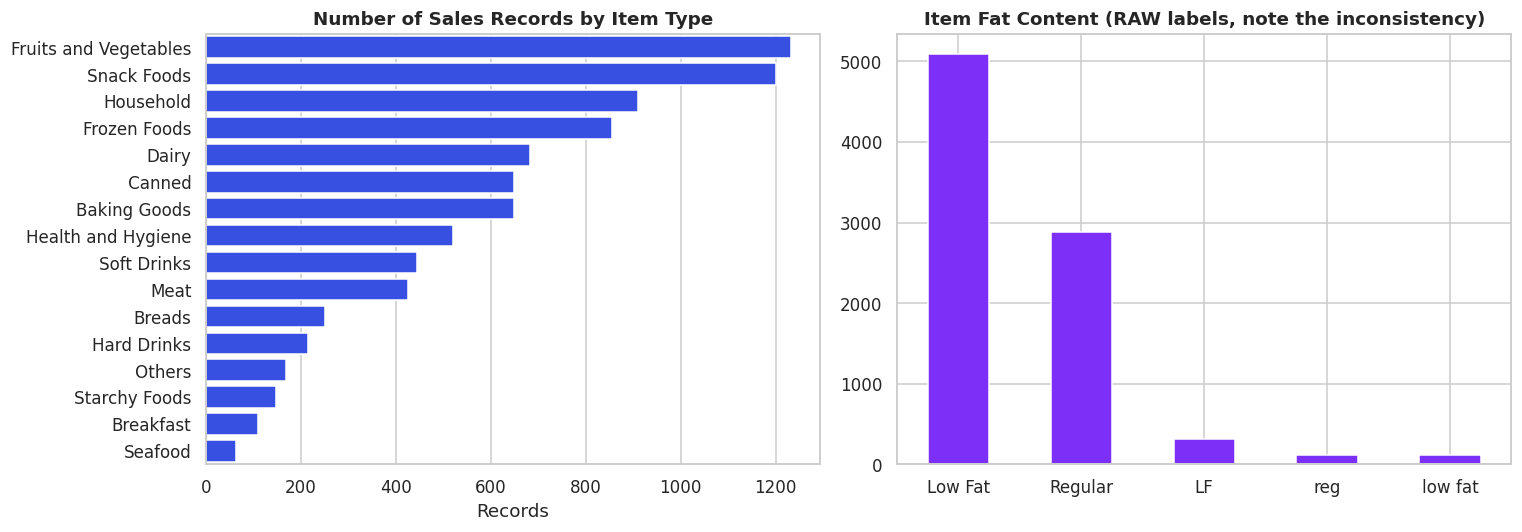

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
order = raw['Item Type'].value_counts()
sns.barplot(x=order.values, y=order.index, ax=ax[0], color='#1a3cff')
ax[0].set_title('Number of Sales Records by Item Type'); ax[0].set_xlabel('Records'); ax[0].set_ylabel('')
raw['Item Fat Content'].value_counts().plot.bar(ax=ax[1], color='#7b2ff7')
ax[1].set_title('Item Fat Content (RAW labels, note the inconsistency)'); ax[1].set_xlabel(''); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

## Task 1.2: Types and locations of BlinkIT outlets

In [4]:
outlet_profile = (raw.groupby('Outlet Identifier')
    .agg(Outlet_Type=('Outlet Type','first'), Location_Tier=('Outlet Location Type','first'),
         Established=('Outlet Establishment Year','first'), Sizes_Recorded=('Outlet Size', lambda s: ', '.join(sorted(s.unique()))),
         Records=('Sales','size')).reset_index())
outlet_profile

,Outlet Identifier,Outlet_Type,Location_Tier,Established,Sizes_Recorded,Records
0,OUT010,Grocery Store,Tier 3,2011,"High, Medium, Small",555
1,OUT013,Supermarket Type1,Tier 3,2014,High,932
2,OUT017,Supermarket Type1,Tier 2,2020,"High, Medium, Small",926
3,OUT018,Supermarket Type2,Tier 3,2022,Medium,928
4,OUT019,Grocery Store,Tier 1,2018,Small,528
5,OUT027,Supermarket Type3,Tier 3,2018,Medium,935
6,OUT035,Supermarket Type1,Tier 2,2017,Small,930
7,OUT045,Supermarket Type1,Tier 2,2015,"High, Medium, Small",929
8,OUT046,Supermarket Type1,Tier 1,2016,Small,930
9,OUT049,Supermarket Type1,Tier 1,2012,Medium,930


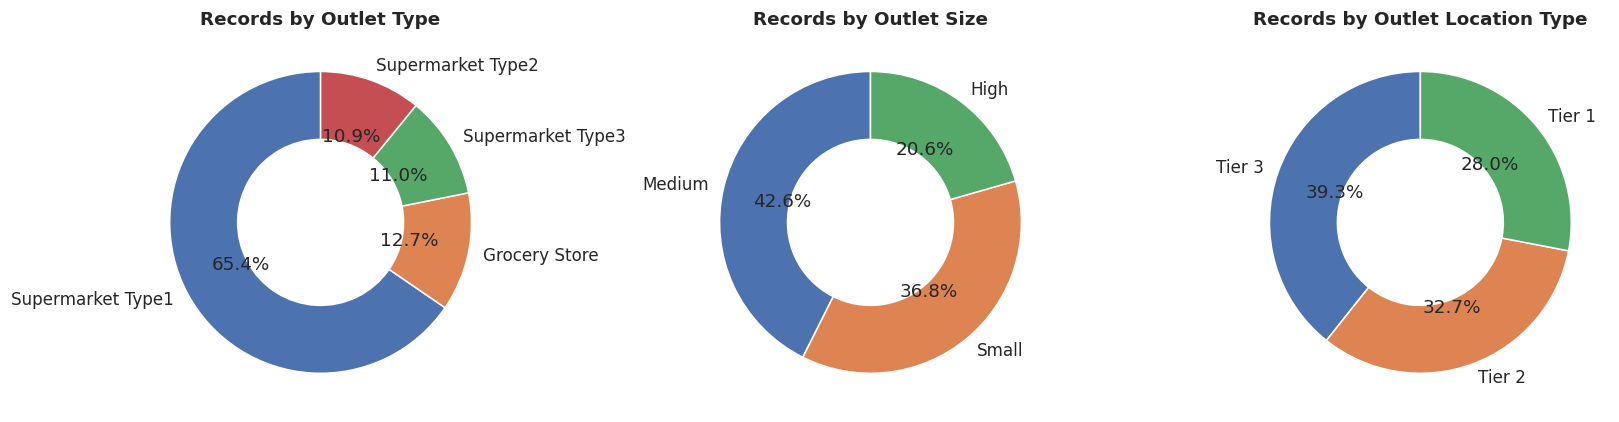

Outlet Location Type  Tier 1  Tier 2  Tier 3   All
Outlet Type                                       
Grocery Store            528       0     555  1083
Supermarket Type1       1860    2785     932  5577
Supermarket Type2          0       0     928   928
Supermarket Type3          0       0     935   935
All                     2388    2785    3350  8523


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ['Outlet Type', 'Outlet Size', 'Outlet Location Type']):
    raw[col].value_counts().plot.pie(ax=a, autopct='%1.1f%%', startangle=90, wedgeprops={'width':0.45}, ylabel='')
    a.set_title(f'Records by {col}')
plt.tight_layout(); plt.show()
print(pd.crosstab(raw['Outlet Type'], raw['Outlet Location Type'], margins=True))

**Observation (1.2):** There are 10 outlets across 3 location tiers and 4 outlet types (Grocery Store, Supermarket Type 1/2/3). Supermarket Type 1 dominates the footprint (about 65% of records). Only OUT010 and OUT019 are grocery stores, and OUT018 and OUT027 are the single Type 2 and Type 3 outlets. **Data flag:** outlets OUT010, OUT017 and OUT045 each show *three different sizes* in the data, even though one outlet should have one size. This is reported in Objective 2 and left as supplied.

## Task 1.3: How much is BlinkIT selling overall?

Total Sales                 1201681.49
Number of Sales Records        8523.00
Average Sales per Record        140.99
Median Sales per Record         143.01
Minimum                          31.29
Maximum                         266.89
Std. Deviation                   62.28


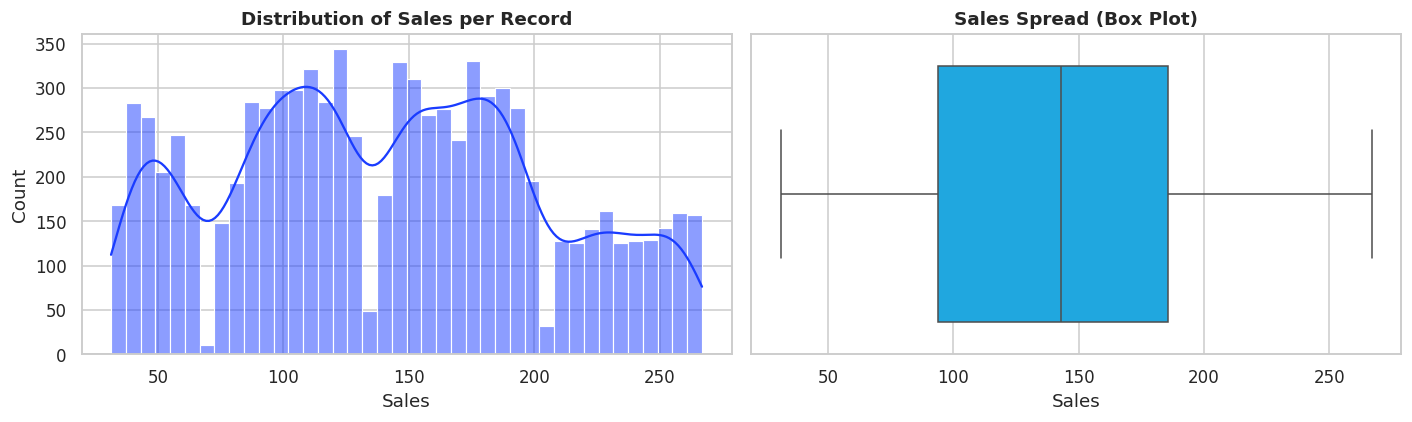

In [6]:
total = raw['Sales'].sum()
summary = pd.Series({
    'Total Sales': total, 'Number of Sales Records': len(raw), 'Average Sales per Record': raw['Sales'].mean(),
    'Median Sales per Record': raw['Sales'].median(), 'Minimum': raw['Sales'].min(), 'Maximum': raw['Sales'].max(),
    'Std. Deviation': raw['Sales'].std()}).round(2)
print(summary.to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(raw['Sales'], bins=40, kde=True, ax=ax[0], color='#1a3cff'); ax[0].set_title('Distribution of Sales per Record')
sns.boxplot(x=raw['Sales'], ax=ax[1], color='#00b4ff'); ax[1].set_title('Sales Spread (Box Plot)')
plt.tight_layout(); plt.show()

## Task 1.4: Overall customer rating and product performance

Average rating : 3.97
Median rating  : 4.0
Rating >= 4    : 76.4% of records
Rating < 3     : 5.0% of records


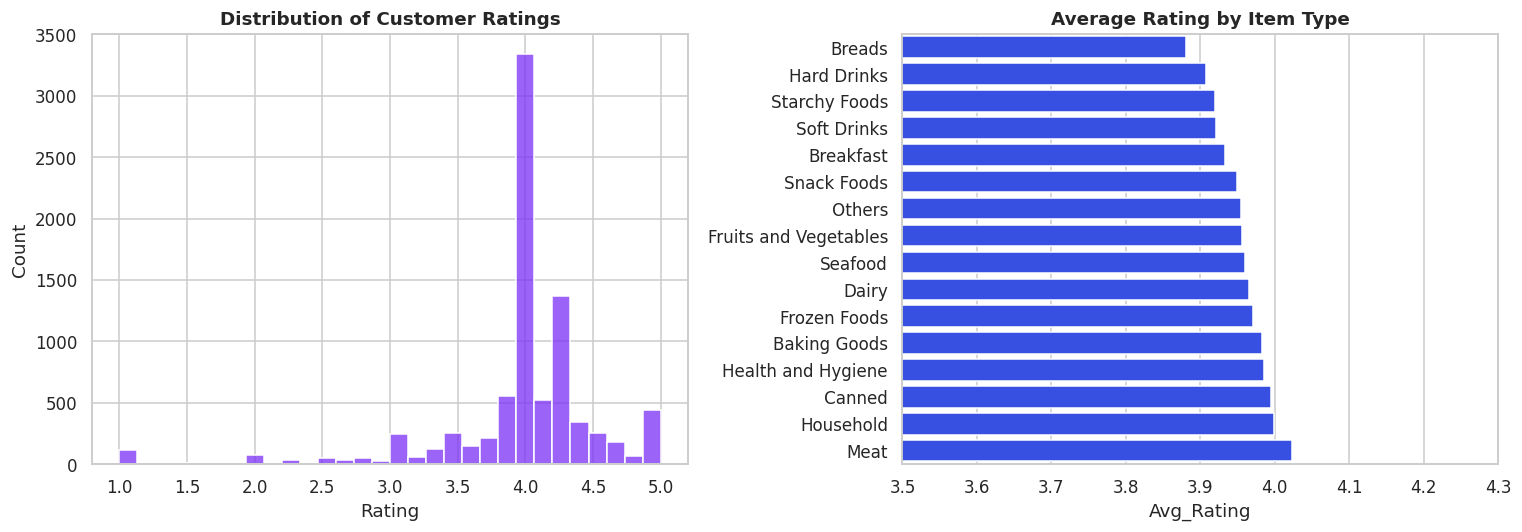

,Avg_Rating,Avg_Sales
Item Type,,
Meat,4.023,139.882
Household,3.999,149.425
Canned,3.994,139.764
Health and Hygiene,3.986,130.819
Baking Goods,3.983,126.381
Frozen Foods,3.971,138.503
Dairy,3.966,148.499
Seafood,3.959,141.842
Fruits and Vegetables,3.956,144.581


In [7]:
print('Average rating :', round(raw['Rating'].mean(), 2))
print('Median rating  :', raw['Rating'].median())
print('Rating >= 4    :', f"{(raw['Rating']>=4).mean():.1%} of records")
print('Rating < 3     :', f"{(raw['Rating']<3).mean():.1%} of records")
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(raw['Rating'], bins=30, ax=ax[0], color='#7b2ff7'); ax[0].set_title('Distribution of Customer Ratings')
r = raw.groupby('Item Type').agg(Avg_Rating=('Rating','mean'), Avg_Sales=('Sales','mean')).sort_values('Avg_Rating')
sns.barplot(x=r['Avg_Rating'], y=r.index, ax=ax[1], color='#1a3cff'); ax[1].set_xlim(3.5, 4.3); ax[1].set_title('Average Rating by Item Type'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()
r.round(3).sort_values('Avg_Rating', ascending=False)

# Objective 2: Make Sure the Available Information Is Reliable


## Task 2.1: Missing information

In [8]:
miss = pd.DataFrame({'Missing': raw.isna().sum(), '% Missing': (raw.isna().mean()*100).round(2)})
print(miss[miss.Missing > 0])
print()
print('Missing Item Weight by outlet:'); print(raw[raw['Item Weight'].isna()]['Outlet Identifier'].value_counts().to_string())
print('\nRecords with Item Visibility = 0 (a product that is sold cannot have zero shelf visibility):', (raw['Item Visibility']==0).sum(),
      f"({(raw['Item Visibility']==0).mean():.1%})")

             Missing  % Missing
Item Weight     1463      17.17

Missing Item Weight by outlet:
Outlet Identifier
OUT027    935
OUT019    528

Records with Item Visibility = 0 (a product that is sold cannot have zero shelf visibility): 526 (6.2%)


**Findings (2.1):**
- **Item Weight** is missing for 1,463 records (17.2%). All of them come from just two outlets (OUT019 and OUT027), so this is a systematic recording gap, not random. Every other column is complete.
- **Item Visibility = 0** in 526 records (6.2%). This is not realistic and is probably a recording gap that was stored as zero.
- *Handling:* left as is. Weight-based calculations use only the 7,060 records that have a weight; the zero visibility values stay in the visibility calculations.

## Task 2.2: Repeated information

In [9]:
print('Fully duplicated rows            :', raw.duplicated().sum())
print('Repeated (Item, Outlet) pairs    :', raw.duplicated(subset=['Item Identifier','Outlet Identifier']).sum())
print('Item Identifiers appearing >1x   :', (raw['Item Identifier'].value_counts() > 1).sum(), 'of', raw['Item Identifier'].nunique())
print()
print('Records per product (summary):'); print(raw['Item Identifier'].value_counts().describe().round(2).to_string())

Fully duplicated rows            : 0
Repeated (Item, Outlet) pairs    : 0
Item Identifiers appearing >1x   : 1550 of 1559

Records per product (summary):
count    1559.00
mean        5.47
std         1.53
min         1.00
25%         4.00
50%         5.00
75%         6.50
max        10.00


**Findings (2.2):** there are **no duplicate records**. The repeated Item Identifiers are expected, because the same product is sold through several outlets, and no product appears twice in the same outlet.

## Task 2.3: Unusually high or low values (outliers)

         Column  Lower fence  Upper fence  # Low  # High  % of rows
          Sales      -43.899      323.370      0       0       0.00
         Rating        3.700        4.500   1246     685      22.66
Item Visibility       -0.074        0.196      0     144       1.69
    Item Weight       -3.341       28.964      0       0       0.00


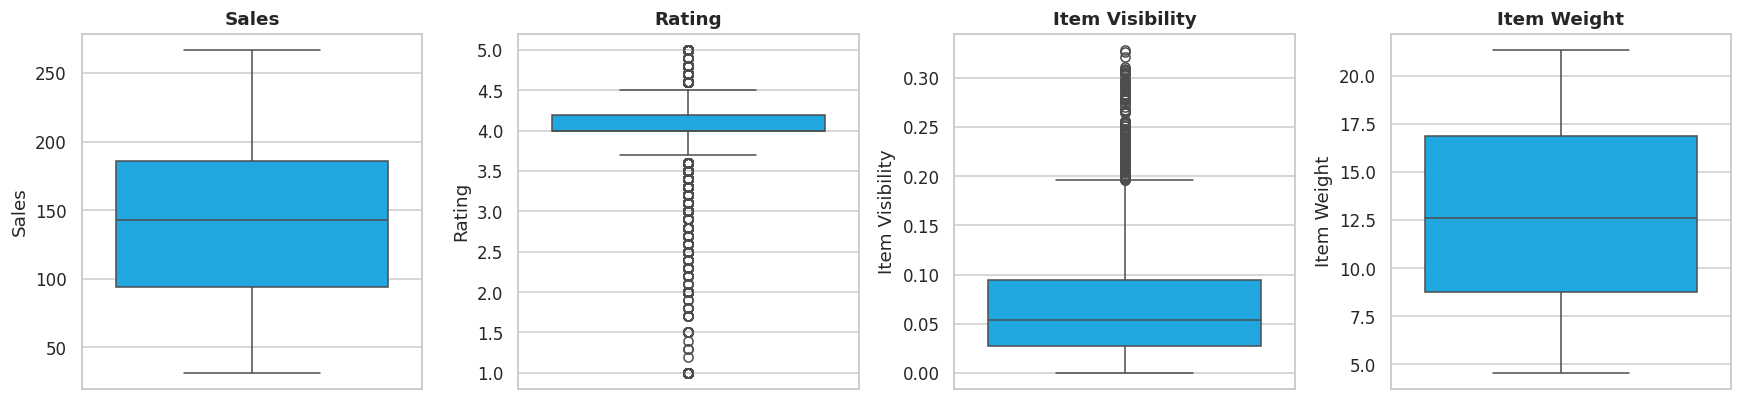

In [10]:
num = ['Sales','Rating','Item Visibility','Item Weight']
rows = []
for c in num:
    x = raw[c].dropna()
    q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_lo, n_hi = (x < lo).sum(), (x > hi).sum()
    rows.append([c, round(lo,3), round(hi,3), n_lo, n_hi, round((n_lo+n_hi)/len(x)*100,2)])
out = pd.DataFrame(rows, columns=['Column','Lower fence','Upper fence','# Low','# High','% of rows'])
print(out.to_string(index=False))
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, c in zip(ax, num):
    sns.boxplot(y=raw[c], ax=a, color='#00b4ff'); a.set_title(c)
plt.tight_layout(); plt.show()

**Findings (2.3):**
- **Sales** and **Item Weight** have no outliers (Sales runs from about 31 to 267).
- **Item Visibility** has 144 high values (1.7%), a long right tail of products that take a large share of shelf space. They are plausible.
- **Rating** is flagged on both ends (1,246 low and 685 high, about 22.7% of records), but only because ratings are tightly bunched around 4.0, which makes the IQR fences very narrow (3.7 to 4.5). Every value is a valid rating from 1 to 5. The low ratings (1 to 2.5) are real unhappy-customer signals.
- *Handling:* nothing removed.

## Task 2.4: Consistency of similar information

In [11]:
print('Item Fat Content labels as supplied:'); print(raw['Item Fat Content'].value_counts().to_string())
nc = raw['Item Identifier'].str.startswith('NC')
print('\nNon-consumable items (ID starts with NC) carrying a fat-content label:', nc.sum(), '(they cannot really be "Low Fat" or "Regular")')
print(raw[nc]['Item Fat Content'].value_counts().to_string())
print('\nOutlet Size conflicts (an outlet should have only one size):')
chk = raw.groupby('Outlet Identifier')['Outlet Size'].nunique()
print(raw[raw['Outlet Identifier'].isin(chk[chk>1].index)].groupby(['Outlet Identifier','Outlet Size']).size().unstack(fill_value=0))

Item Fat Content labels as supplied:
Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112

Non-consumable items (ID starts with NC) carrying a fat-content label: 1599 (they cannot really be "Low Fat" or "Regular")
Item Fat Content
Low Fat    1477
LF           94
low fat      28

Outlet Size conflicts (an outlet should have only one size):
Outlet Size        High  Medium  Small
Outlet Identifier                     
OUT010              233     265     57
OUT017              314     244    368
OUT045              274     329    326


### Prepare the analysis table (adds helper columns only, no values changed)

In [12]:
df = raw.copy()
df.columns = [c.strip().replace(' ', '_') for c in df.columns]           # names only, e.g. 'Item Weight' -> 'Item_Weight'
df['Item_Category'] = df['Item_Identifier'].str[:2].map({'FD':'Food','DR':'Drinks','NC':'Non-Consumable'})   # from the ID prefix
df['Outlet_Age'] = 2026 - df['Outlet_Establishment_Year']
df['Weight_Bucket'] = pd.cut(df['Item_Weight'], bins=[0,8,12,16,25], labels=['<8','8-12','12-16','16+'])      # stays blank where weight is missing
df['Visibility_Bucket'] = pd.qcut(df['Item_Visibility'], 5, labels=['Very Low','Low','Medium','High','Very High'])
df['Rating_Bucket'] = pd.cut(df['Rating'], bins=[0,2.99,3.99,4.5,5.0], labels=['<3','3-3.9','4-4.5','4.6-5'])
print('Shape:', df.shape, '| original 12 columns identical to the raw file:', df.iloc[:, :12].equals(raw.set_axis(df.columns[:12], axis=1)))
print('Missing Item_Weight still present (not filled):', df['Item_Weight'].isna().sum())
df.head()

Shape: (8523, 17) | original 12 columns identical to the raw file: True
Missing Item_Weight still present (not filled): 1463


,Item_Fat_Content,Item_Identifier,Item_Type,Outlet_Establishment_Year,Outlet_Identifier,Outlet_Location_Type,Outlet_Size,Outlet_Type,Item_Visibility,Item_Weight,Sales,Rating,Item_Category,Outlet_Age,Weight_Bucket,Visibility_Bucket,Rating_Bucket
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0,Food,14,12-16,High,4.6-5
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0,Non-Consumable,4,8-12,Very Low,4.6-5
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0,Food,10,12-16,Low,4.6-5
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0,Food,12,12-16,Medium,4.6-5
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0,Drinks,11,16+,Low,4.6-5


# Objective 3: What Is Driving Better Sales Performance?

## Task 3.1: Which types of products are selling more?

,Total_Sales,Avg_Sales,Records,Avg_Rating,Share_%,Cum_Share_%
Item_Type,,,,,,
Fruits and Vegetables,178124.08,144.58,1232,3.96,14.82,14.82
Snack Foods,175433.92,146.19,1200,3.95,14.60,29.42
Household,135976.53,149.42,910,4.00,11.32,40.74
Frozen Foods,118558.88,138.50,856,3.97,9.87,50.60
Dairy,101276.46,148.50,682,3.97,8.43,59.03
Canned,90706.73,139.76,649,3.99,7.55,66.58
Baking Goods,81894.74,126.38,648,3.98,6.82,73.39
Health and Hygiene,68025.84,130.82,520,3.99,5.66,79.06
Meat,59449.86,139.88,425,4.02,4.95,84.00


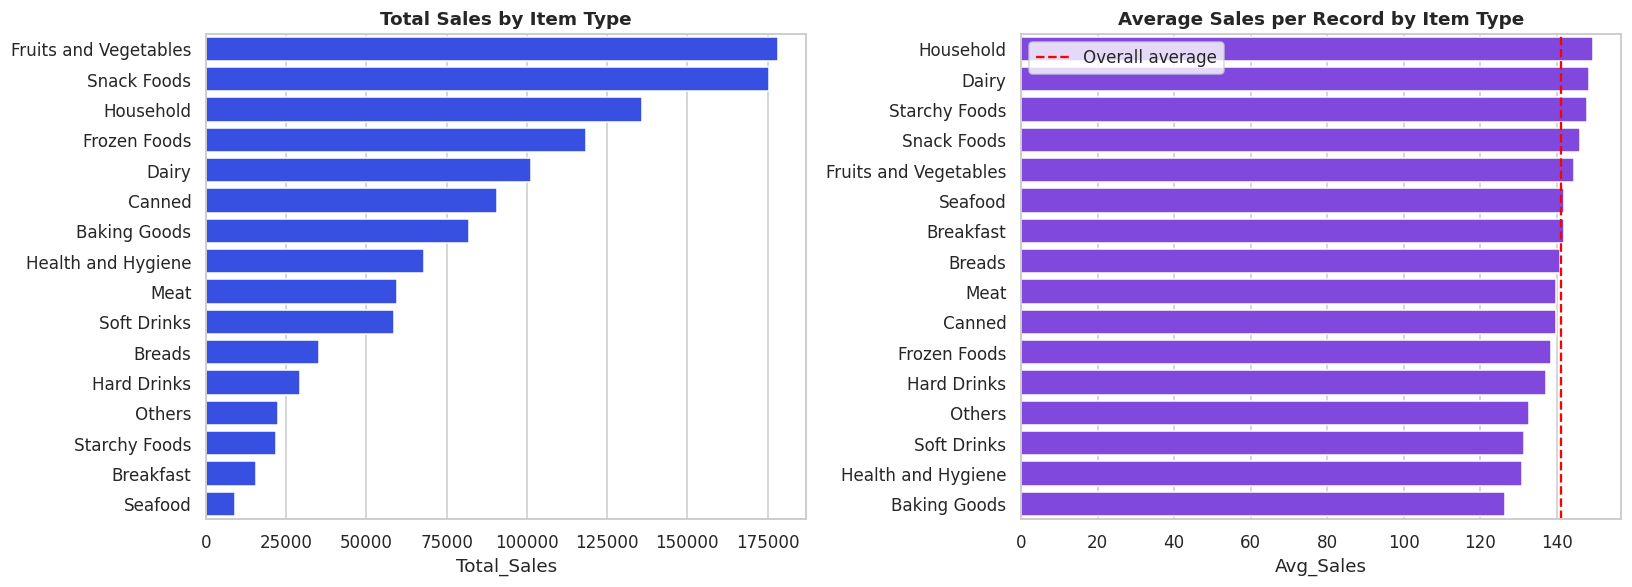

In [13]:
it = (df.groupby('Item_Type').agg(Total_Sales=('Sales','sum'), Avg_Sales=('Sales','mean'), Records=('Sales','size'), Avg_Rating=('Rating','mean'))
        .sort_values('Total_Sales', ascending=False))
it['Share_%'] = (it['Total_Sales']/it['Total_Sales'].sum()*100)
it['Cum_Share_%'] = it['Share_%'].cumsum()
display(it.round(2))
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.barplot(x=it['Total_Sales'], y=it.index, ax=ax[0], color='#1a3cff'); ax[0].set_title('Total Sales by Item Type'); ax[0].set_ylabel('')
a2 = it.sort_values('Avg_Sales', ascending=False)
sns.barplot(x=a2['Avg_Sales'], y=a2.index, ax=ax[1], color='#7b2ff7'); ax[1].axvline(df['Sales'].mean(), color='red', ls='--', label='Overall average'); ax[1].legend()
ax[1].set_title('Average Sales per Record by Item Type'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

,sum,mean
Item_Fat_Content,,
LF,43857.1,138.8
Low Fat,717390.8,141.0
Regular,409413.1,141.7
low fat,15071.7,134.6
reg,15948.7,136.3


,sum,mean
Item_Category,,
Drinks,104650.2,131.0
Food,870577.0,142.1
Non-Consumable,226454.3,141.6


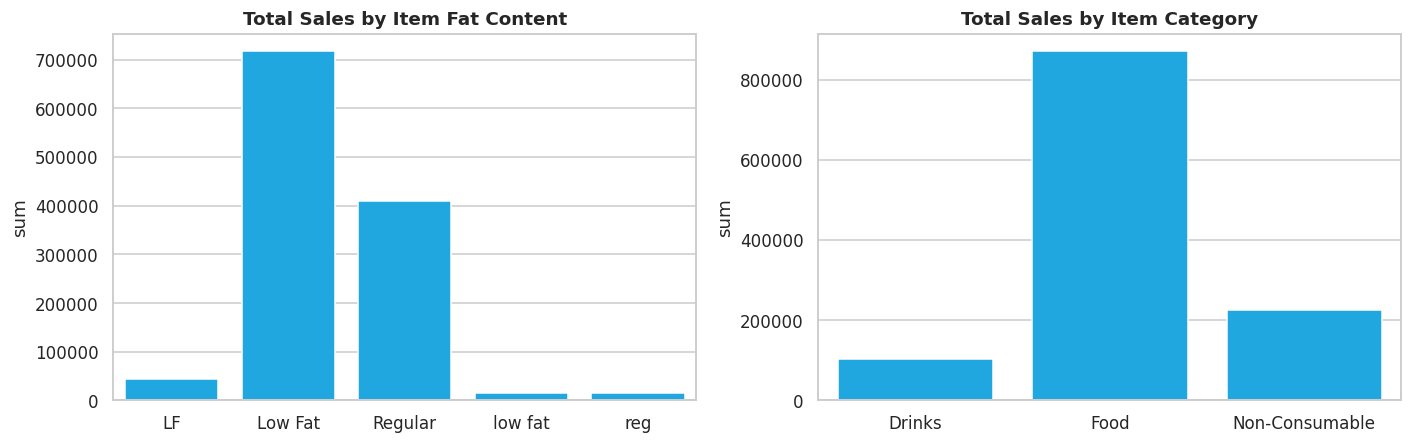

ANOVA across Item Types: F = 7.16, p = 0.0000


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, col in zip(ax, ['Item_Fat_Content','Item_Category']):
    g = df.groupby(col)['Sales'].agg(['sum','mean']).round(1); display(g)
    sns.barplot(x=g.index, y=g['sum'], ax=a, color='#00b4ff'); a.set_title(f'Total Sales by {col.replace("_"," ")}'); a.set_xlabel('')
plt.tight_layout(); plt.show()
# Is the difference in average sales across item types statistically real?
groups = [g['Sales'].values for _, g in df.groupby('Item_Type')]
print('ANOVA across Item Types: F = %.2f, p = %.4f' % stats.f_oneway(*groups))

**Observation (3.1):**
- *Fruits & Vegetables* (14.8%), *Snack Foods* (14.6%) and *Household* (11.3%) are the top three categories and together bring in about **41%** of sales. The top five categories bring in 59%.
- These categories lead mainly because they have **more records** (a wider product range). On a per-record basis the best categories are *Household* (149.4), *Dairy* (148.5) and *Starchy Foods* (147.8), while *Baking Goods* (126.4), *Health & Hygiene* (130.8) and *Soft Drinks* (131.5) are the weakest.
- The ANOVA is significant (p < 0.001), so differences in average sales between categories are statistically real, even though they are modest in size. Drinks (131.0 per record) trail Food (142.1) and Non-Consumables (141.6).
- Fat content (shown with the five raw labels) makes almost no difference. Reading the labels together, Low Fat / low fat / LF average about 140.7 per record and Regular / reg about 141.5. The small label groups (`LF`, `low fat`, `reg`) look slightly lower only because they are small samples.

## Task 3.2: Which types of outlets are performing better?

In [15]:
def perf(col):
    g = df.groupby(col).agg(Outlets=('Outlet_Identifier','nunique'), Total_Sales=('Sales','sum'), Avg_Sales_per_Record=('Sales','mean'), Records=('Sales','size'), Avg_Rating=('Rating','mean'))
    g['Sales_per_Outlet'] = g['Total_Sales']/g['Outlets']
    return g.round(2)
for c in ['Outlet_Type','Outlet_Location_Type','Outlet_Size']:
    print(f'--- by {c}'); display(perf(c))

--- by Outlet_Type


,Outlets,Total_Sales,Avg_Sales_per_Record,Records,Avg_Rating,Sales_per_Outlet
Outlet_Type,,,,,,
Grocery Store,2,151939.15,140.29,1083,3.99,75969.57
Supermarket Type1,6,787549.89,141.21,5577,3.96,131258.32
Supermarket Type2,1,131477.78,141.68,928,3.97,131477.78
Supermarket Type3,1,130714.67,139.80,935,3.95,130714.67


--- by Outlet_Location_Type


,Outlets,Total_Sales,Avg_Sales_per_Record,Records,Avg_Rating,Sales_per_Outlet
Outlet_Location_Type,,,,,,
Tier 1,3,336397.81,140.87,2388,3.98,112132.60
Tier 2,3,393150.65,141.17,2785,3.96,131050.22
Tier 3,4,472133.03,140.94,3350,3.96,118033.26


--- by Outlet_Size


,Outlets,Total_Sales,Avg_Sales_per_Record,Records,Avg_Rating,Sales_per_Outlet
Outlet_Size,,,,,,
High,4,248991.59,142.04,1753,3.95,62247.90
Medium,6,507895.74,139.88,3631,3.98,84649.29
Small,6,444794.17,141.70,3139,3.96,74132.36


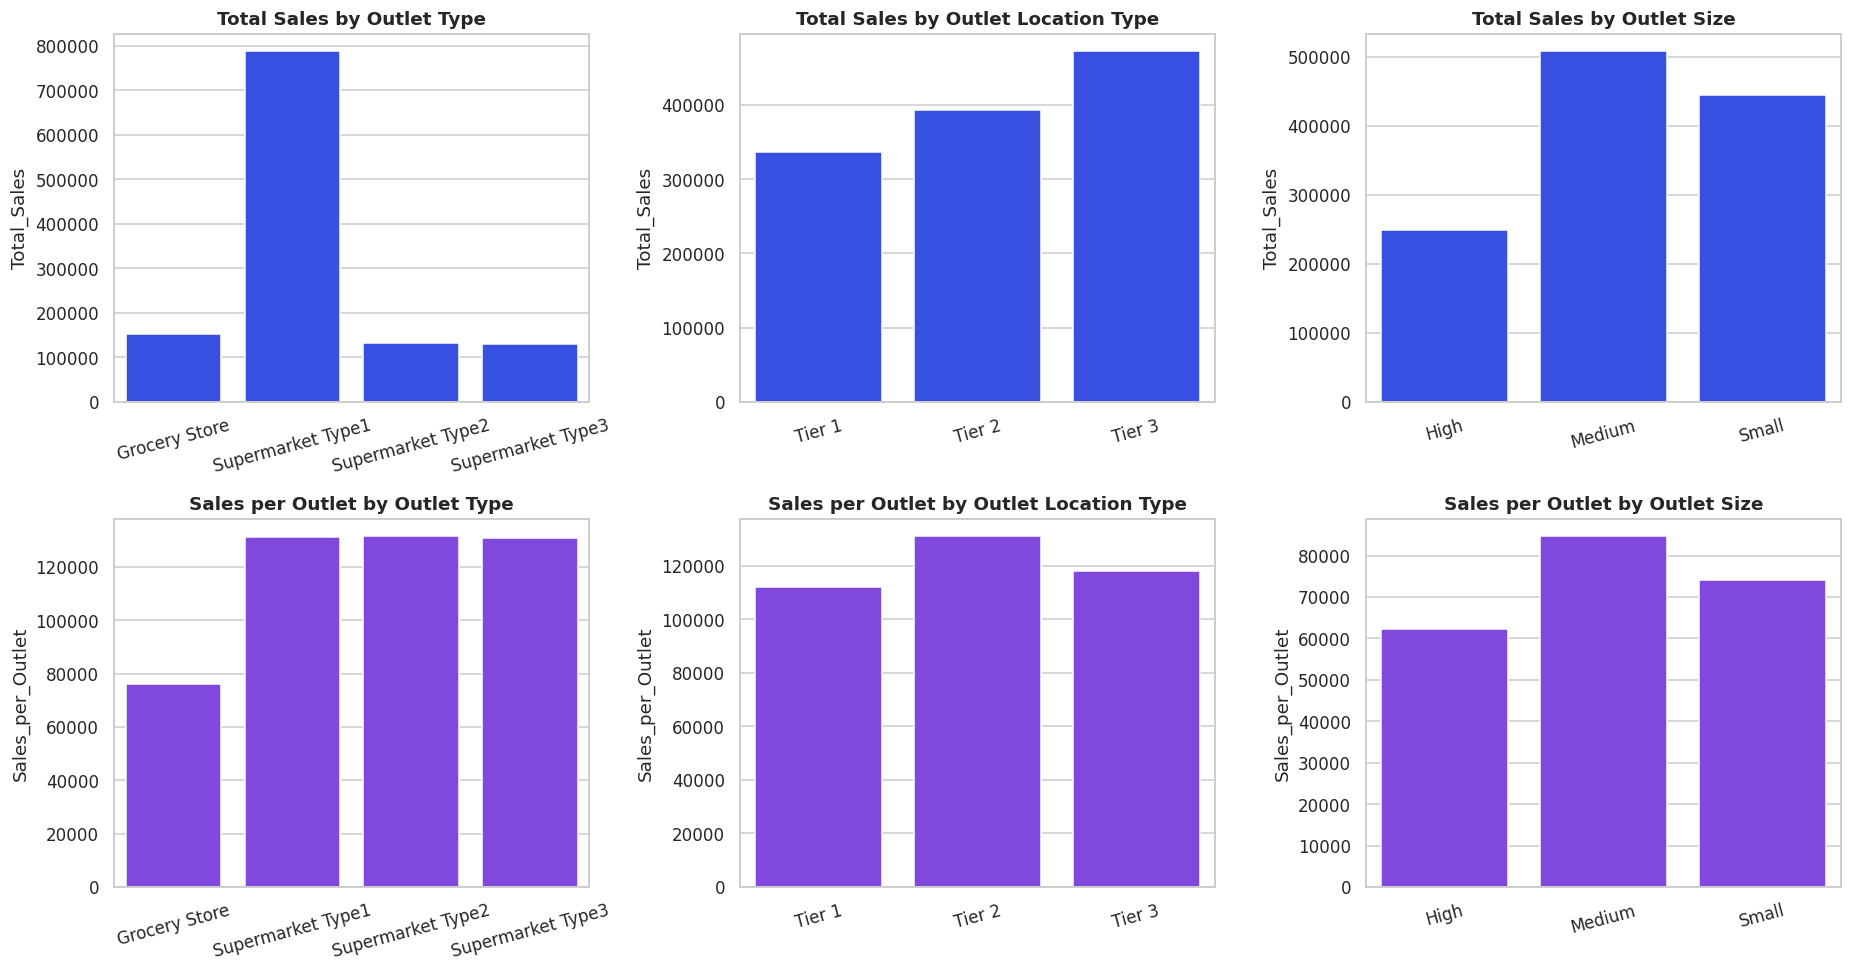

In [16]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for j, c in enumerate(['Outlet_Type','Outlet_Location_Type','Outlet_Size']):
    g = perf(c)
    sns.barplot(x=g.index, y=g['Total_Sales'], ax=ax[0, j], color='#1a3cff'); ax[0, j].set_title(f'Total Sales by {c.replace("_"," ")}')
    sns.barplot(x=g.index, y=g['Sales_per_Outlet'], ax=ax[1, j], color='#7b2ff7'); ax[1, j].set_title(f'Sales per Outlet by {c.replace("_"," ")}')
    ax[0,j].set_xlabel(''); ax[1,j].set_xlabel(''); ax[0,j].tick_params(axis='x', rotation=15); ax[1,j].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

,Outlet_Identifier,Outlet_Type,Outlet_Location_Type,Outlet_Establishment_Year,Total_Sales,Avg_Sales,Records,Avg_Rating,Share_%
6,OUT035,Supermarket Type1,Tier 2,2017,133103.91,143.12,930,3.94,11.08
8,OUT046,Supermarket Type1,Tier 1,2016,132113.37,142.06,930,3.96,10.99
1,OUT013,Supermarket Type1,Tier 3,2014,131809.02,141.43,932,3.95,10.97
3,OUT018,Supermarket Type2,Tier 3,2022,131477.78,141.68,928,3.97,10.94
7,OUT045,Supermarket Type1,Tier 2,2015,130942.78,140.95,929,3.96,10.90
5,OUT027,Supermarket Type3,Tier 3,2018,130714.67,139.80,935,3.95,10.88
9,OUT049,Supermarket Type1,Tier 1,2012,130476.86,140.30,930,3.99,10.86
2,OUT017,Supermarket Type1,Tier 2,2020,129103.96,139.42,926,3.98,10.74
0,OUT010,Grocery Store,Tier 3,2011,78131.57,140.78,555,3.98,6.50
4,OUT019,Grocery Store,Tier 1,2018,73807.58,139.79,528,4.00,6.14


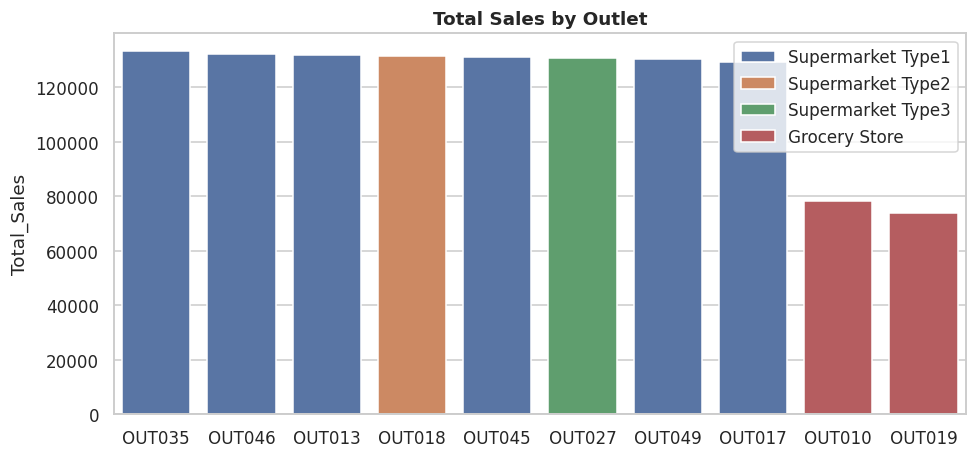

Total sales differ mostly because the NUMBER of records differs, so compare average sales per record:
ANOVA Outlet Type: F = 0.22, p = 0.8824


In [17]:
og = (df.groupby(['Outlet_Identifier','Outlet_Type','Outlet_Location_Type','Outlet_Establishment_Year'])
        .agg(Total_Sales=('Sales','sum'), Avg_Sales=('Sales','mean'), Records=('Sales','size'), Avg_Rating=('Rating','mean'))
        .reset_index().sort_values('Total_Sales', ascending=False))
og['Share_%'] = og['Total_Sales']/og['Total_Sales'].sum()*100
display(og.round(2))
plt.figure(figsize=(10, 4.5))
sns.barplot(data=og, x='Outlet_Identifier', y='Total_Sales', hue='Outlet_Type', dodge=False)
plt.title('Total Sales by Outlet'); plt.xlabel(''); plt.legend(title='', loc='upper right'); plt.show()
print('Total sales differ mostly because the NUMBER of records differs, so compare average sales per record:')
print('ANOVA Outlet Type: F = %.2f, p = %.4f' % stats.f_oneway(*[g['Sales'].values for _, g in df.groupby('Outlet_Type')]))

## Task 3.3: Are visibility, weight, ratings and outlet characteristics connected with sales?

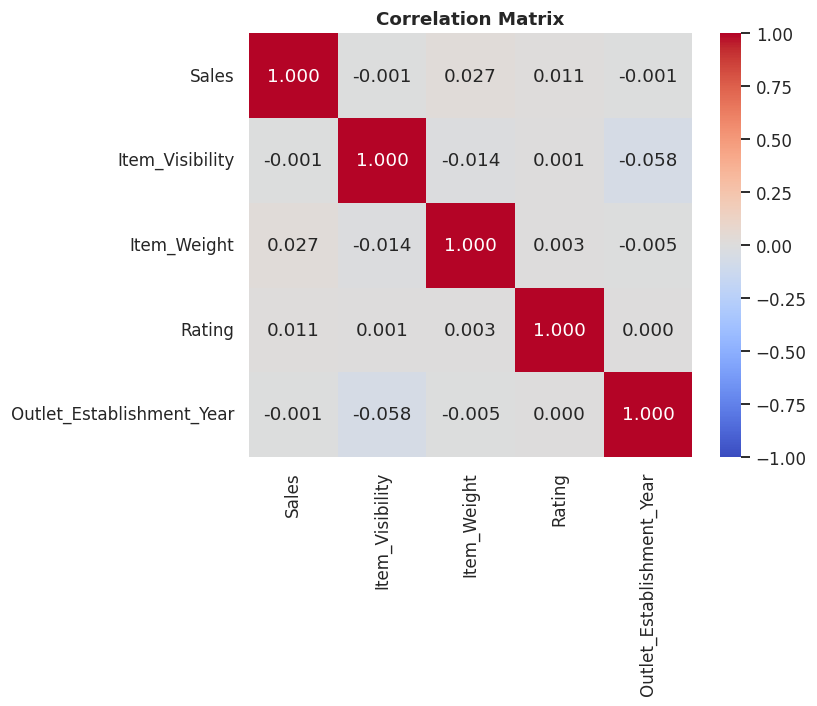

                   Factor  Records used  Pearson r  p-value  Spearman rho  p-value
          Item_Visibility          8523    -0.0013   0.9034        0.0057   0.5996
              Item_Weight          7060     0.0271   0.0226        0.0308   0.0096
                   Rating          8523     0.0113   0.2957       -0.0004   0.9671
Outlet_Establishment_Year          8523    -0.0007   0.9518       -0.0018   0.8656


In [18]:
corr = df[['Sales','Item_Visibility','Item_Weight','Rating','Outlet_Establishment_Year']].corr()
plt.figure(figsize=(6.5, 5)); sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm', center=0, vmin=-1, vmax=1); plt.title('Correlation Matrix'); plt.show()
res = []
for c in ['Item_Visibility','Item_Weight','Rating','Outlet_Establishment_Year']:
    d = df[[c,'Sales']].dropna(); r, p = stats.pearsonr(d[c], d['Sales']); rho, p2 = stats.spearmanr(d[c], d['Sales'])
    res.append([c, len(d), round(r,4), round(p,4), round(rho,4), round(p2,4)])
print(pd.DataFrame(res, columns=['Factor','Records used','Pearson r','p-value','Spearman rho','p-value']).to_string(index=False))

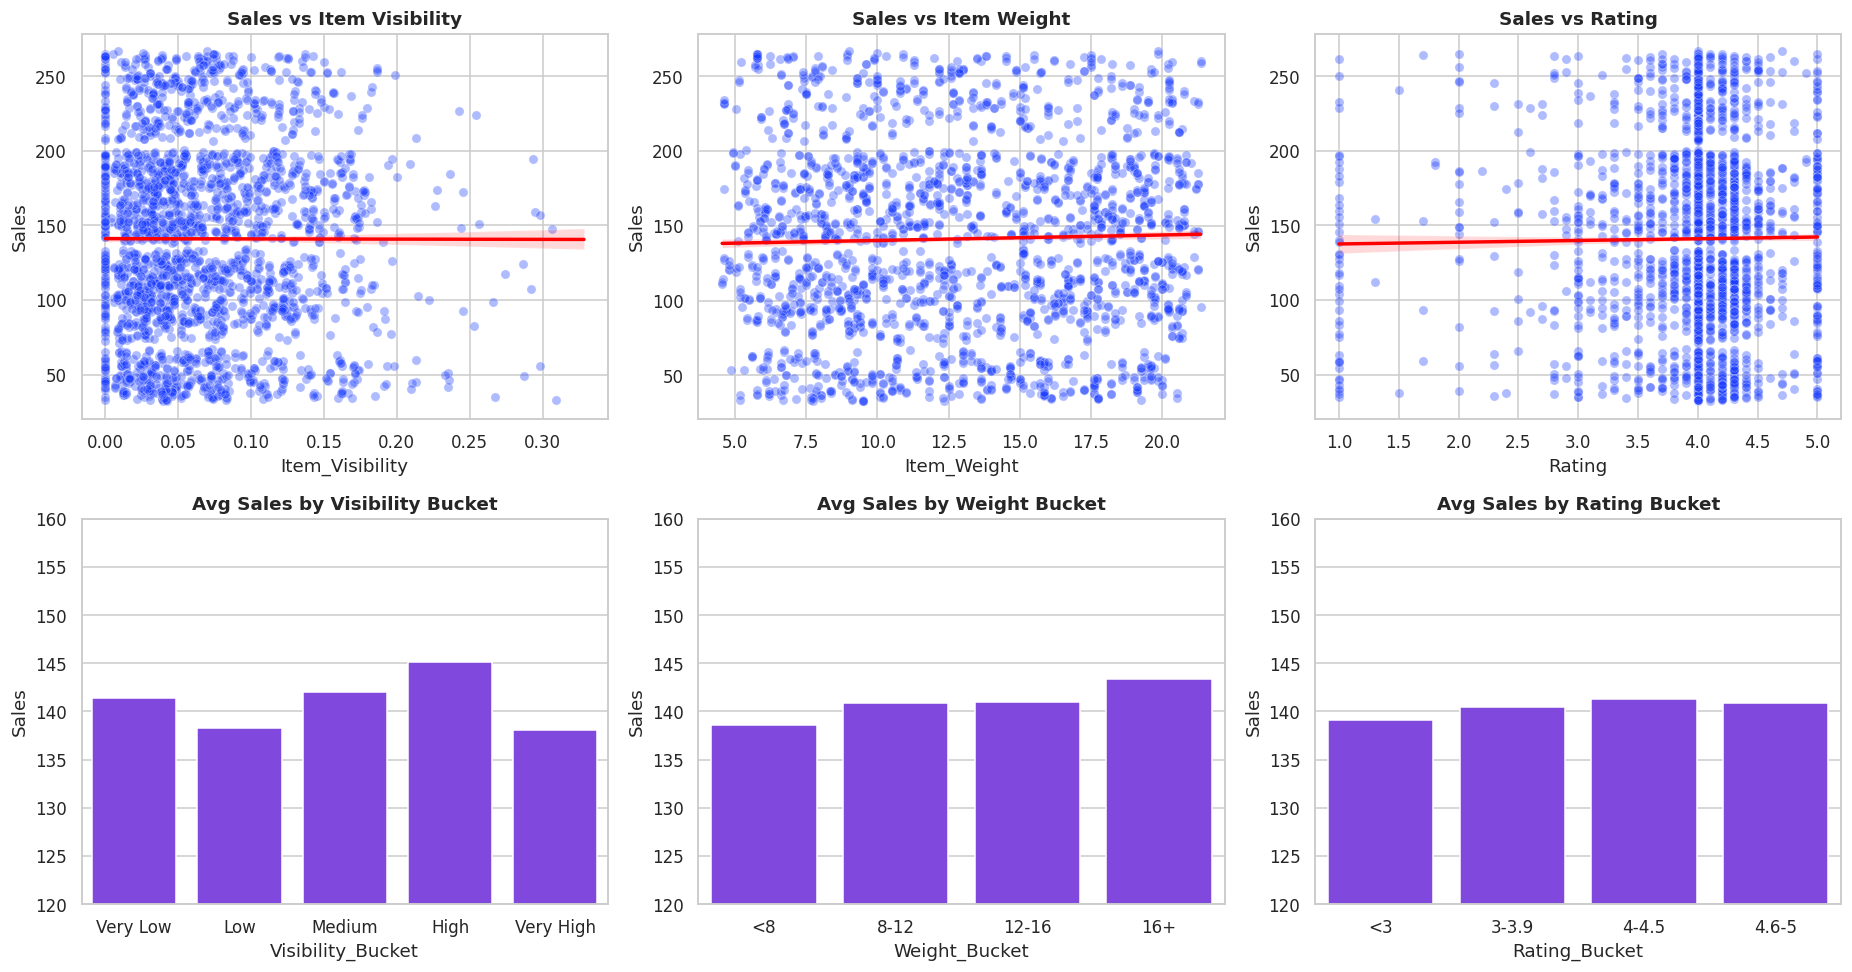

In [19]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for a, c in zip(ax.ravel()[:3], ['Item_Visibility','Item_Weight','Rating']):
    sns.scatterplot(data=df.sample(2500, random_state=1), x=c, y='Sales', alpha=.35, ax=a, color='#1a3cff'); sns.regplot(data=df, x=c, y='Sales', scatter=False, ax=a, color='red'); a.set_title(f'Sales vs {c.replace("_"," ")}')
for a, c in zip(ax.ravel()[3:], ['Visibility_Bucket','Weight_Bucket','Rating_Bucket']):
    sns.barplot(data=df, x=c, y='Sales', ax=a, color='#7b2ff7', errorbar=None); a.set_title(f'Avg Sales by {c.replace("_"," ")}'); a.set_ylim(120, 160)
plt.tight_layout(); plt.show()

**Findings (3.3):** all correlations with sales are essentially zero (|r| < 0.03).
- **Item Visibility, Rating and Outlet Age:** no relationship (p-values 0.30 to 0.97).
- **Item Weight** (7,060 records that have a weight): technically significant (r = 0.027, p = 0.023), but it explains less than 0.1% of the variation in sales, so it is not practically important.
- Sales per record are also nearly flat across visibility, weight and rating bands in the bar charts.

In plain terms: a more visible, heavier or higher-rated product does not sell more per record in this data. These levers alone will not lift sales, and the differences that exist come from **volume and range** (how many products and outlets), not from the value of each sale.

## Task 3.4: Better-performing vs lower-performing products and outlets

In [20]:
prod = (df.groupby(['Item_Identifier','Item_Type']).agg(Total_Sales=('Sales','sum'), Outlets_Sold_In=('Outlet_Identifier','nunique'), Avg_Rating=('Rating','mean'), Avg_Visibility=('Item_Visibility','mean'), Weight=('Item_Weight','first'))
          .reset_index().sort_values('Total_Sales', ascending=False))
top, bot = prod.head(50), prod.tail(50)
cmp = pd.DataFrame({'Top 50 products': top[['Total_Sales','Outlets_Sold_In','Avg_Rating','Avg_Visibility','Weight']].mean(),
                    'Bottom 50 products': bot[['Total_Sales','Outlets_Sold_In','Avg_Rating','Avg_Visibility','Weight']].mean()}).round(3)
display(cmp)
print('Top 50 mix   :', top['Item_Type'].value_counts().head(5).to_dict())
print('Bottom 50 mix:', bot['Item_Type'].value_counts().head(5).to_dict())

,Top 50 products,Bottom 50 products
Total_Sales,1880.614,143.962
Outlets_Sold_In,7.880,2.980
Avg_Rating,3.969,3.984
Avg_Visibility,0.069,0.066
Weight,12.597,11.800


Top 50 mix   : {'Fruits and Vegetables': 9, 'Frozen Foods': 8, 'Dairy': 8, 'Snack Foods': 7, 'Household': 5}
Bottom 50 mix: {'Snack Foods': 9, 'Household': 7, 'Dairy': 6, 'Frozen Foods': 5, 'Canned': 4}


If top products differ from bottom products mainly in **how many outlets stock them**, then *distribution* (availability), not product quality, is what separates winners from laggards.

In [21]:
# Record-level: top 25% vs bottom 25% of sales
q_hi, q_lo = df['Sales'].quantile([.75, .25])
hi, lo = df[df['Sales']>=q_hi], df[df['Sales']<=q_lo]
cols = ['Item_Visibility','Item_Weight','Rating','Outlet_Age']
print(pd.DataFrame({'High-sales records (top 25%)': hi[cols].mean(), 'Low-sales records (bottom 25%)': lo[cols].mean()}).round(3))
for c in ['Outlet_Type','Outlet_Location_Type']:
    print(); print(pd.DataFrame({'High (top 25%)': hi[c].value_counts(normalize=True), 'Low (bottom 25%)': lo[c].value_counts(normalize=True)}).round(3))
# outlet comparison
display(og[['Outlet_Identifier','Outlet_Type','Outlet_Location_Type','Records','Total_Sales','Avg_Sales']].round(1).assign(Gap_vs_Best=lambda d: (d['Total_Sales']/d['Total_Sales'].max()-1).round(3)))

                 High-sales records (top 25%)  Low-sales records (bottom 25%)
Item_Visibility                         0.066                           0.066
Item_Weight                            13.053                          12.770
Rating                                  3.965                           3.965
Outlet_Age                              9.537                           9.535

                   High (top 25%)  Low (bottom 25%)
Outlet_Type                                        
Grocery Store               0.123             0.129
Supermarket Type1           0.657             0.650
Supermarket Type2           0.114             0.107
Supermarket Type3           0.106             0.113

                      High (top 25%)  Low (bottom 25%)
Outlet_Location_Type                                  
Tier 3                         0.398             0.397
Tier 2                         0.326             0.321
Tier 1                         0.275             0.282


,Outlet_Identifier,Outlet_Type,Outlet_Location_Type,Records,Total_Sales,Avg_Sales,Gap_vs_Best
6,OUT035,Supermarket Type1,Tier 2,930,133103.9,143.1,0.000
8,OUT046,Supermarket Type1,Tier 1,930,132113.4,142.1,-0.007
1,OUT013,Supermarket Type1,Tier 3,932,131809.0,141.4,-0.010
3,OUT018,Supermarket Type2,Tier 3,928,131477.8,141.7,-0.012
7,OUT045,Supermarket Type1,Tier 2,929,130942.8,141.0,-0.016
5,OUT027,Supermarket Type3,Tier 3,935,130714.7,139.8,-0.018
9,OUT049,Supermarket Type1,Tier 1,930,130476.9,140.3,-0.020
2,OUT017,Supermarket Type1,Tier 2,926,129104.0,139.4,-0.030
0,OUT010,Grocery Store,Tier 3,555,78131.6,140.8,-0.413
4,OUT019,Grocery Store,Tier 1,528,73807.6,139.8,-0.445


# Objective 4: Help Management Make Better Business Decisions

## Task 4.1: Products contributing more to sales

Top 10 individual products by total sales:


,Item_Identifier,Item_Type,Total_Sales,Outlets_Sold_In,Avg_Rating,Avg_Visibility,Weight
976,FDU12,Baking Goods,2371.01,9,4.14,0.09,15.50
921,FDT07,Fruits and Vegetables,2306.90,9,4.00,0.08,5.82
1454,NCQ06,Household,2294.71,9,4.12,0.05,13.00
616,FDL58,Snack Foods,2111.65,8,3.86,0.07,5.78
1279,NCB31,Household,2104.73,8,3.84,0.13,6.24
1141,FDX31,Fruits and Vegetables,2104.46,9,4.06,0.01,20.35
359,FDF05,Frozen Foods,2103.13,8,3.90,0.03,17.50
866,FDR59,Breads,2096.58,8,3.79,0.07,14.50
753,FDP28,Frozen Foods,2087.85,8,4.21,0.09,13.65
148,FDA04,Frozen Foods,2072.07,8,4.15,0.07,11.30


Top 20% of products account for 36.6% of sales (1,559 products)


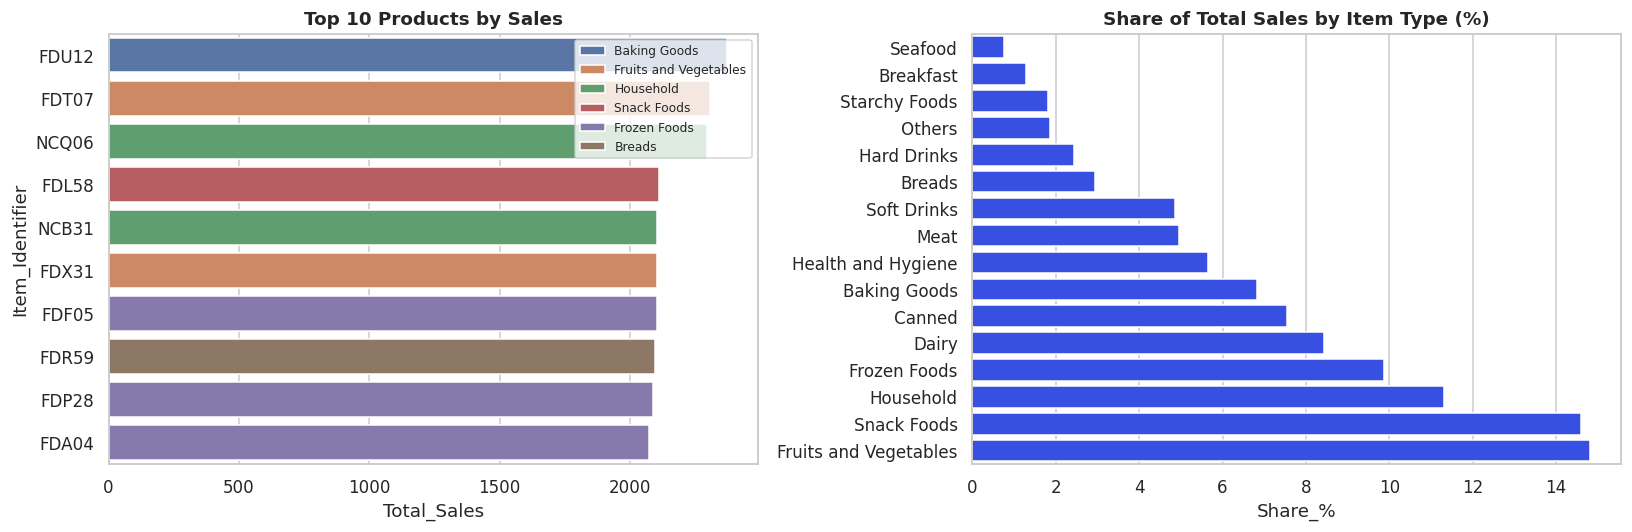

In [22]:
print('Top 10 individual products by total sales:'); display(prod.head(10).round(2))
tp = prod['Total_Sales'].cumsum()/prod['Total_Sales'].sum()
print(f'Top 20% of products account for {tp.iloc[int(len(prod)*0.2)]:.1%} of sales (1,559 products)')
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=prod.head(10), y='Item_Identifier', x='Total_Sales', hue='Item_Type', dodge=False, ax=ax[0]); ax[0].set_title('Top 10 Products by Sales'); ax[0].legend(fontsize=8)
it_s = it.sort_values('Share_%'); sns.barplot(x=it_s['Share_%'], y=it_s.index, ax=ax[1], color='#1a3cff'); ax[1].set_title('Share of Total Sales by Item Type (%)'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

## Task 4.2: Outlets and locations performing better

Outlet_Type,Grocery Store,Supermarket Type1,Supermarket Type2,Supermarket Type3
Outlet_Location_Type,,,,
Tier 1,73808.0,262590.0,NaN,NaN
Tier 2,NaN,393151.0,NaN,NaN
Tier 3,78132.0,131809.0,131478.0,130715.0


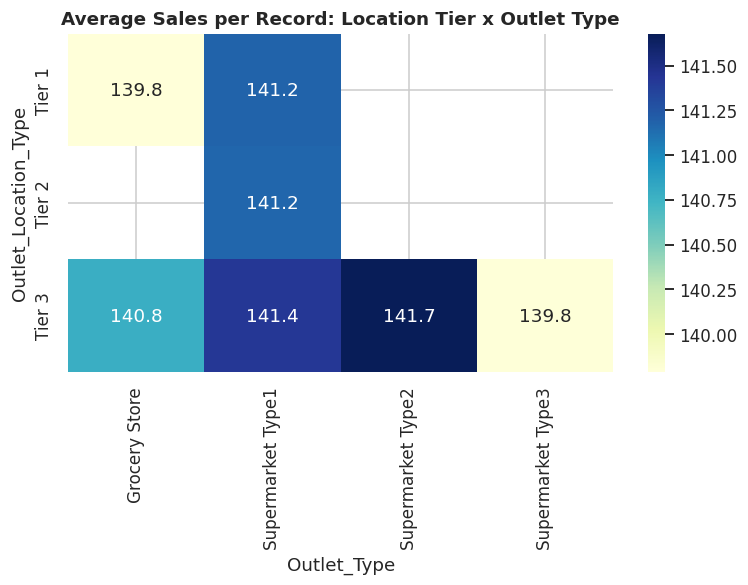

Outlet_Identifier       Outlet_Type Outlet_Location_Type  Total_Sales  Share_%
           OUT035 Supermarket Type1               Tier 2     133103.9     11.1
           OUT046 Supermarket Type1               Tier 1     132113.4     11.0
           OUT013 Supermarket Type1               Tier 3     131809.0     11.0
           OUT018 Supermarket Type2               Tier 3     131477.8     10.9
           OUT045 Supermarket Type1               Tier 2     130942.8     10.9


In [23]:
loc = df.pivot_table(index='Outlet_Location_Type', columns='Outlet_Type', values='Sales', aggfunc='sum').round(0)
display(loc)
plt.figure(figsize=(8,4)); sns.heatmap(df.pivot_table(index='Outlet_Location_Type', columns='Outlet_Type', values='Sales', aggfunc='mean'), annot=True, fmt='.1f', cmap='YlGnBu')
plt.title('Average Sales per Record: Location Tier x Outlet Type'); plt.show()
print(og[['Outlet_Identifier','Outlet_Type','Outlet_Location_Type','Total_Sales','Share_%']].head(5).round(1).to_string(index=False))

## Task 4.3: Where can performance be improved?

In [24]:
# 1) Weakest categories (avg sales below overall mean) 2) weakest outlets 3) low-rated products with meaningful sales
overall = df['Sales'].mean()
weak_cat = it[it['Avg_Sales'] < overall][['Total_Sales','Avg_Sales','Records','Avg_Rating']].sort_values('Avg_Sales')
print('Categories with below-average sales per record (overall avg = %.1f):' % overall); display(weak_cat.round(2))
print('Lowest-selling outlets:'); display(og.tail(3)[['Outlet_Identifier','Outlet_Type','Outlet_Location_Type','Total_Sales','Records']].round(1))
lowr = prod[(prod['Avg_Rating']<3.5)].sort_values('Total_Sales', ascending=False).head(10)
print('High-selling products with low average rating (<3.5): quality / experience risk'); display(lowr.round(2))
low_rated_share = (df['Rating']<3).mean()
print(f'Share of records rated below 3: {low_rated_share:.1%}')

Categories with below-average sales per record (overall avg = 141.0):


,Total_Sales,Avg_Sales,Records,Avg_Rating
Item_Type,,,,
Baking Goods,81894.74,126.38,648,3.98
Health and Hygiene,68025.84,130.82,520,3.99
Soft Drinks,58514.17,131.49,445,3.92
Others,22451.89,132.85,169,3.95
Hard Drinks,29334.68,137.08,214,3.91
Frozen Foods,118558.88,138.50,856,3.97
Canned,90706.73,139.76,649,3.99
Meat,59449.86,139.88,425,4.02
Breads,35379.12,140.95,251,3.88


Lowest-selling outlets:


,Outlet_Identifier,Outlet_Type,Outlet_Location_Type,Total_Sales,Records
2,OUT017,Supermarket Type1,Tier 2,129104.0,926
0,OUT010,Grocery Store,Tier 3,78131.6,555
4,OUT019,Grocery Store,Tier 1,73807.6,528


High-selling products with low average rating (<3.5): quality / experience risk


,Item_Identifier,Item_Type,Total_Sales,Outlets_Sold_In,Avg_Rating,Avg_Visibility,Weight
538,FDJ55,Meat,1797.82,8,3.42,0.03,12.80
1202,FDY45,Snack Foods,1524.01,6,3.02,0.02,17.50
481,FDI20,Fruits and Vegetables,1478.71,7,3.29,0.05,19.10
531,FDJ44,Fruits and Vegetables,1395.42,8,3.45,0.12,12.30
41,DRF23,Hard Drinks,1389.62,8,3.39,0.12,4.61
1233,FDZ23,Baking Goods,1305.07,7,3.24,0.07,17.75
930,FDT16,Frozen Foods,1303.34,5,3.48,0.05,9.90
485,FDI26,Canned,1248.14,7,3.33,0.04,5.94
956,FDT48,Baking Goods,1189.85,6,3.32,0.04,4.92
1047,FDV37,Canned,1181.96,6,3.30,0.09,13.00


Share of records rated below 3: 5.0%


## Task 4.4: Practical suggestions



### Recommendations
1. **Widen the range at the two grocery stores (OUT010, OUT019).** They have ~40% fewer records than supermarkets at the same sales per record. Bringing each close to a supermarket's range could add roughly 53k to 57k per store (about 110k combined, or ~9% of current sales). This is an illustrative estimate that assumes per-record sales stay the same.
2. **Stock best-selling products in more outlets.** The top 50 products sell in ~8 outlets and the bottom 50 in ~3. Check which top sellers are missing from outlets and add them. Review products sold in 3 outlets or fewer for delisting or promotion.
3. **Grow the strong categories:** Household, Dairy, Starchy Foods and Fruits & Vegetables. Give them more range and promotion.
4. **Fix the weak categories:** *Baking Goods* (lowest at 126.4 per record, with 648 records), *Health & Hygiene* and *Soft Drinks*. Review pricing, pack sizes, and bundling with strong categories.
5. **Do not rely on shelf visibility or weight to lift sales.** The data shows no link. Test any display changes in a small pilot before a wider rollout.
6. **Watch quality on popular products with poor ratings**, such as FDY45 (rating 3.02), FDI20 (3.29) and FDZ23 (3.24). *Breads*, *Hard Drinks*, *Soft Drinks* and *Starchy Foods* have the lowest category ratings.
7. **Fix the data at source** (the raw data was deliberately left as is): one size per outlet, mandatory item weight, no zero visibility, and fixed values for fat content. Add **date/time and quantity** fields so trends, seasonality and pricing can be analysed next.
8. **Before opening new outlets**, note that Supermarket Types 1, 2 and 3 earn about the same. If Type 1 is cheaper to run, it looks like the better-value format (cost data was not provided, so this needs checking).
